<a href="https://colab.research.google.com/github/Dineshkumar-DK19/GCEE-HCL/blob/main/Phase%202%20-%20ML/UNIT%202/NN_sentimental_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Class Sentiment Analysis: Deep Learning Architecture Comparison & Automated Hyperparameter Tuning

### Project Objective
This notebook builds, optimizes, and compares four neural network architectures—**Dense Neural Network (NN)**, **Bidirectional SimpleRNN**, **Bidirectional LSTM**, and **Bidirectional GRU**—on a multi-class sentiment analysis dataset (`Negative`, `Neutral`, `Positive`). Using **Keras Tuner**, each model is automatically tuned across predefined hyperparameter ranges to identify the highest-performing architecture and optimal parameter configuration.

In [1]:
# Block 1: Install required libraries
!pip install -q datasets keras-tuner

## Step 1: Dataset Loading & Cleaning
* **Source:** Loads the `Sp1786/multiclass-sentiment-analysis-dataset` directly from Hugging Face, which provides pre-split `train` (~31.2k rows), `validation` (~5.21k rows), and `test` (~5.21k rows) subsets.
* **Data Cleaning:** Converts all text entries to strings and replaces any missing (`None`) values with empty strings (`""`) to prevent tokenization errors.
* **Target Labels:** Extracts the 3 sentiment classes (`0`: Negative, `1`: Neutral, `2`: Positive) into NumPy arrays for model training and evaluation.

In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Load dataset
ds = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")
print("Columns:", ds["train"].column_names)

# 2. Extract & clean texts and labels (0: Negative, 1: Neutral, 2: Positive)
train_texts = [str(t) if t is not None else "" for t in ds["train"]["text"]]
train_labels = np.array(ds["train"]["label"])

val_texts = [str(t) if t is not None else "" for t in ds["validation"]["text"]]
val_labels = np.array(ds["validation"]["label"])

test_texts = [str(t) if t is not None else "" for t in ds["test"]["text"]]
test_labels = np.array(ds["test"]["label"])

NUM_CLASSES = len(np.unique(train_labels))
print(f"Total Classes: {NUM_CLASSES} -> {np.unique(train_labels)}")



README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

Columns: ['id', 'text', 'label', 'sentiment']
Total Classes: 3 -> [0 1 2]


## Step 2: Tokenization & Sequence Padding
Deep learning models require fixed-length numerical inputs rather than raw text:
* **Vocabulary Indexing (`Tokenizer`):** Fits exclusively on the training split (`VOCAB_SIZE = 20000`) to prevent data leakage, assigning integer IDs to the most frequent words and mapping unknown words to `<OOV>`.
* **Sequence Conversion & Padding (`pad_sequences`):** Converts every sentence into a sequence of word indices and standardizes all rows to a fixed length (`MAX_LEN = 60`) using post-padding (`0`s added at the end).

In [6]:
# 3. Tokenization & Padding
VOCAB_SIZE = 10000
MAX_LEN = 60

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN, padding="post")
X_val = pad_sequences(tokenizer.texts_to_sequences(val_texts), maxlen=MAX_LEN, padding="post")
X_test = pad_sequences(tokenizer.texts_to_sequences(test_texts), maxlen=MAX_LEN, padding="post")

## Step 3: Model Architectures, Automated Tuning & Evaluation
* **Architectures Tested:**
  * **NN:** `Embedding` $\rightarrow$ `GlobalAveragePooling1D` $\rightarrow$ `Dense (ReLU)` (non-sequential baseline).
  * **RNN / LSTM / GRU:** `Embedding` $\rightarrow$ `Bidirectional` recurrent layers to capture forward and backward sequence context.
  * **Output Head:** `Dropout` for regularization followed by `Dense(3, activation="softmax")` compiled with `Adam` and `sparse_categorical_crossentropy`.
* **Automated Hyperparameter Search (`kt.RandomSearch`):** Explores combinations of `embed_dim` (`64, 128`), `units` (`64–128`), `dropout` (`0.2–0.4`), and `learning_rate` (`0.001, 0.0005`) over 4 trials per model, using `EarlyStopping` to prevent overfitting.
* **Model Ranking:** Evaluates each architecture's best trial on the unseen test split and ranks all four models by **Test Accuracy (%)**.

In [7]:
import keras_tuner as kt
from tensorflow.keras import layers, models

def build_model_fn(model_type):
    def build_model(hp):
        model = models.Sequential()

        embed_dim = hp.Choice("embed_dim", values=[64, 128])
        units = hp.Int("units", min_value=64, max_value=128, step=32)
        dropout_rate = hp.Float("dropout", min_value=0.2, max_value=0.4, step=0.1)
        lr = hp.Choice("learning_rate", values=[1e-3, 5e-4])

        # mask_zero removed so cuDNN GPU runs without error!
        model.add(layers.Embedding(VOCAB_SIZE, embed_dim, input_length=MAX_LEN))

        if model_type == "NN":
            model.add(layers.GlobalAveragePooling1D())
            model.add(layers.Dense(units, activation="relu"))
        elif model_type == "RNN":
            model.add(layers.Bidirectional(layers.SimpleRNN(units)))
        elif model_type == "LSTM":
            model.add(layers.Bidirectional(layers.LSTM(units)))
        elif model_type == "GRU":
            model.add(layers.Bidirectional(layers.GRU(units)))

        model.add(layers.Dropout(dropout_rate))
        model.add(layers.Dense(NUM_CLASSES, activation="softmax"))

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )
        return model
    return build_model

model_types = ["NN", "RNN", "LSTM", "GRU"]
results = []

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

for m_type in model_types:
    print(f"\n================ Tuning {m_type} ================")
    tuner = kt.RandomSearch(
        build_model_fn(m_type),
        objective="val_accuracy",
        max_trials=4,
        executions_per_trial=1,
        directory="multiclass_sentiment_v3",
        project_name=f"{m_type}_tuning",
        overwrite=True
    )

    tuner.search(
        X_train, train_labels,
        epochs=10,
        batch_size=128,
        validation_data=(X_val, val_labels),
        callbacks=[early_stop],
        verbose=1
    )

    best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
    best_model = tuner.get_best_models(num_models=1)[0]

    val_loss, val_acc = best_model.evaluate(X_val, val_labels, verbose=0)
    test_loss, test_acc = best_model.evaluate(X_test, test_labels, verbose=0)

    results.append({
        "Model": m_type,
        "Val Accuracy (%)": round(val_acc * 100, 2),
        "Test Accuracy (%)": round(test_acc * 100, 2),
        "Best Hyperparameters": str(best_hp.values)
    })

pd.set_option("display.max_colwidth", None)
df_results = pd.DataFrame(results).sort_values(by="Test Accuracy (%)", ascending=False)

print("\n================ FINAL COMPARISON ================")
print(df_results.to_string(index=False))

winner = df_results.iloc[0]
print(f"\nBest Performing Model: {winner['Model']} with {winner['Test Accuracy (%)']}% Test Accuracy")
print(f"Best Parameter Configuration: {winner['Best Hyperparameters']}")

Trial 4 Complete [00h 00m 22s]
val_accuracy: 0.6766570806503296

Best val_accuracy So Far: 0.6860710978507996
Total elapsed time: 00h 01m 25s

================ FINAL COMPARISON ================
Model  Val Accuracy (%)  Test Accuracy (%)                                                     Best Hyperparameters
 LSTM             68.74              68.50 {'embed_dim': 128, 'units': 64, 'dropout': 0.2, 'learning_rate': 0.0005}
  GRU             68.61              68.09 {'embed_dim': 128, 'units': 128, 'dropout': 0.4, 'learning_rate': 0.001}
   NN             68.68              67.79 {'embed_dim': 128, 'units': 128, 'dropout': 0.4, 'learning_rate': 0.001}
  RNN             65.51              64.52 {'embed_dim': 128, 'units': 96, 'dropout': 0.4, 'learning_rate': 0.0005}

Best Performing Model: LSTM with 68.5% Test Accuracy
Best Parameter Configuration: {'embed_dim': 128, 'units': 64, 'dropout': 0.2, 'learning_rate': 0.0005}


## Step 4: Visual Comparison & Best Model Diagnostics
* **Accuracy Comparison Chart:** Plots side-by-side **Validation vs. Test Accuracy (%)** bars across all four tuned architectures to visually highlight the winning model.
* **Confusion Matrix & Classification Report:** Reloads the best-performing model (`LSTM`) from saved tuner checkpoints, generates predictions on `X_test`, and displays a class-wise **Confusion Matrix** alongside **Precision, Recall, and F1-Score** metrics.

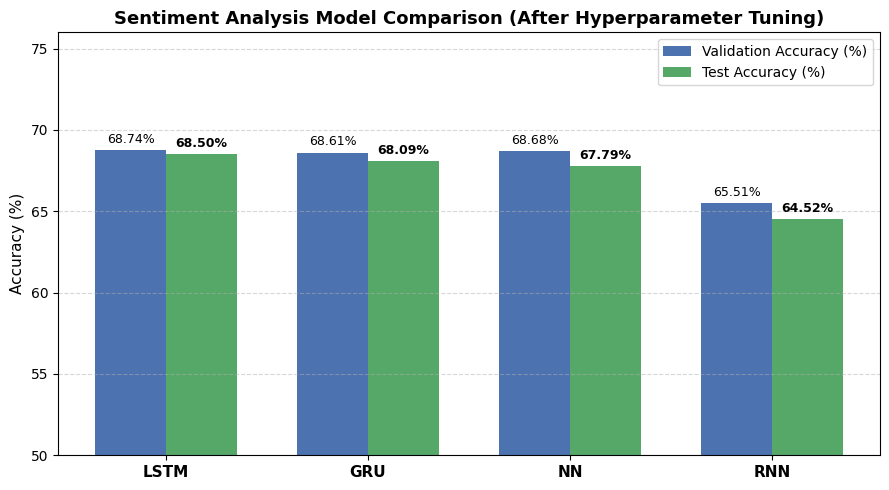

Reloading Tuner from multiclass_sentiment_v3/LSTM_tuning/tuner0.json


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 20 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


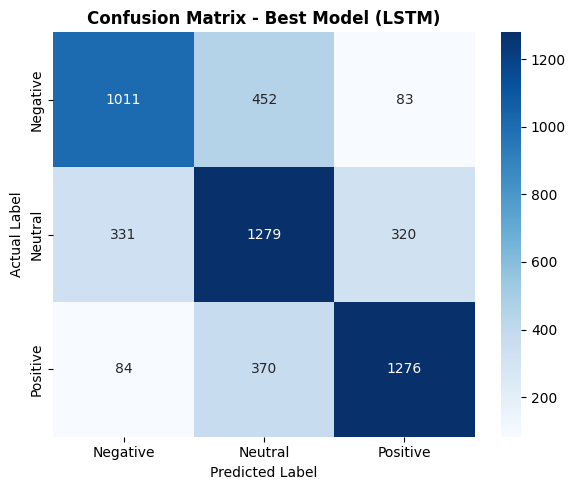


=== Classification Report (Best Model) ===
              precision    recall  f1-score   support

    Negative       0.71      0.65      0.68      1546
     Neutral       0.61      0.66      0.63      1930
    Positive       0.76      0.74      0.75      1730

    accuracy                           0.68      5206
   macro avg       0.69      0.68      0.69      5206
weighted avg       0.69      0.68      0.69      5206



In [8]:
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix


# PART 1: BAR CHART COMPARING VALIDATION VS TEST ACCURACY
# Extract columns from  ranked results DataFrame
models_list = df_results["Model"]
val_acc = df_results["Val Accuracy (%)"]
test_acc = df_results["Test Accuracy (%)"]

# Create x-axis positions: [0, 1, 2, 3] for the 4 models
x = np.arange(len(models_list))
width = 0.35

# Create a blank canvas (fig) and a plotting area (ax) of size 9x5 inches
fig, ax = plt.subplots(figsize=(9, 5))

# Draw two side-by-side bars at each x position:
# Shift validation bars slightly left (- width/2) and test bars slightly right (+ width/2)
rects1 = ax.bar(
    x - width / 2, val_acc, width, label="Validation Accuracy (%)", color="#4C72B0"
)
rects2 = ax.bar(
    x + width / 2, test_acc, width, label="Test Accuracy (%)", color="#55A868"
)

# Add axis labels, chart title, and model names on the x-axis
ax.set_ylabel("Accuracy (%)", fontsize=11)
ax.set_title(
    "Sentiment Analysis Model Comparison (After Hyperparameter Tuning)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xticks(x)  # Set tick positions at 0, 1, 2, 3
ax.set_xticklabels(
    models_list, fontsize=11, fontweight="bold"
)  # Replace 0,1,2,3 with model names
ax.set_ylim(50, 76)
ax.legend()
ax.grid(
    axis="y", linestyle="--", alpha=0.5
)

# Loop through Validation bars and write the exact percentage number above each bar
for rect in rects1:
  h = rect.get_height()
  ax.annotate(
      f"{h:.2f}%",
      xy=(
          rect.get_x() + rect.get_width() / 2,
          h,
      ),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=9,
  )


for rect in rects2:
  h = rect.get_height()
  ax.annotate(
      f"{h:.2f}%",
      xy=(rect.get_x() + rect.get_width() / 2, h),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=9,
      fontweight="bold",
  )

plt.tight_layout()  # Automatically adjust spacing so labels don't get cut off
plt.savefig(
    "model_comparison_chart.png", dpi=300
)  # Save high-res image (300 DPI) to Colab files
plt.show()  # Display the chart on screen



# PART 2: RELOAD WINNING MODEL & GENERATE PREDICTIONS
winner_name = df_results.iloc[0]["Model"]

# Point Keras Tuner to the existing folder where the winning model's weights were saved
best_tuner = kt.RandomSearch(
    build_model_fn(winner_name),
    objective="val_accuracy",
    max_trials=4,
    directory="multiclass_sentiment_v3",
    project_name=f"{winner_name}_tuning",
    overwrite=False,  # IMPORTANT: False tells it NOT to retrain, just load saved results
)

winner_model = best_tuner.get_best_models(num_models=1)[0]
raw_predictions = winner_model.predict(X_test, verbose=0)
y_pred = np.argmax(raw_predictions, axis=1)


# PART 3: CONFUSION MATRIX and CLASSIFICATION REPORT


cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(6, 5))


sns.heatmap(
    cm,
    annot=True,
    fmt="d",  # Format numbers as whole integers ("d" = decimal integer)
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"],
)

plt.title(
    f"Confusion Matrix - Best Model ({winner_name})",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    "confusion_matrix.png", dpi=300
)
plt.show()

print("\n=== Classification Report (Best Model) ===")
print(
    classification_report(
        test_labels, y_pred, target_names=["Negative", "Neutral", "Positive"]
    )
)